In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa va a ejecutar el proyecto de inversión cuyo cuadro de prelaciones se adjunta, con la duración esperada de cada actividad (meses), sus tres estimaciones (optimista $a$, más probable $m$, pesimista $b$, con distribución triangular) y su presupuesto (BAC, k€). El coste de cada actividad se desembolsa uniformemente a lo largo de su duración. Cuando el proyecto termina, la instalación genera un flujo de caja neto mensual de 30 k€ durante 60 meses, pero ese flujo es incierto: entre 20 y 40 k€ (triangular simétrica). La empresa descuenta al 10% anual.

In [4]:
pregunta_1 = "1. Con las duraciones esperadas, calcule el calendario, el camino crítico y el VAN determinista del proyecto (flujo mensual, tasa mensual equivalente).  "
pregunta_2 = "2. Simule 5 000 réplicas: duraciones triangulares e ingreso mensual incierto. De cada réplica obtenga la duración del proyecto y su VAN. Dibuje los histogramas y calcule la media, la desviación típica, P(VAN < 0) y el percentil 5 %.  "
pregunta_3 = "3. ¿Por qué la media del VAN simulado no coincide con el VAN determinista? Separe los dos efectos simulando por separado solo la incertidumbre de las duraciones y solo la del ingreso.  "
pregunta_4 = "4. ¿Qué variables explican la variabilidad del VAN? Calcule la correlación de Spearman del VAN con cada duración y con el ingreso, y compárela con el índice de criticidad de cada actividad. ¿Hay alguna actividad cuya demora *mejore* el VAN? ¿Por qué?  "
pregunta_5 = "5. La empresa puede (a) encargar un estudio de mercado que fije el ingreso en su valor central, o (b) contratar a un subcontratista que fije la duración de la actividad más influyente en su valor esperado. Evalúe qué cambia con cada opción (y con ambas) en la media, la desviación y P(VAN < 0), y qué compra realmente cada una.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Con las duraciones esperadas, calcule el calendario, el camino crítico y el VAN determinista del proyecto (flujo mensual, tasa mensual equivalente).  

2. Simule 5 000 réplicas: duraciones triangulares e ingreso mensual incierto. De cada réplica obtenga la duración del proyecto y su VAN. Dibuje los histogramas y calcule la media, la desviación típica, P(VAN < 0) y el percentil 5 %.  

3. ¿Por qué la media del VAN simulado no coincide con el VAN determinista? Separe los dos efectos simulando por separado solo la incertidumbre de las duraciones y solo la del ingreso.  

4. ¿Qué variables explican la variabilidad del VAN? Calcule la correlación de Spearman del VAN con cada duración y con el ingreso, y compárela con el índice de criticidad de cada actividad. ¿Hay alguna actividad cuya demora *mejore* el VAN? ¿Por qué?  

5. La empresa puede (a) encargar un estudio de mercado que fije el ingreso en su valor central, o (b) contratar a un subcontratista que fije la duración de la actividad más influyente en su valor esperado. Evalúe qué cambia con cada opción (y con ambas) en la media, la desviación y P(VAN < 0), y qué compra realmente cada una.  

In [5]:
#| tbl-cap: "Datos del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, a, m, b , BAC
    ('A'     , '---'      , 4       , 1, 5, 6 , 200),
    ('B'     , '---'      , 6       , 3, 5, 10, 50 ),
    ('C'     , '---'      , 2       , 1, 2, 3 , 200),
    ('D'     , 'A,B,C'    , 6       , 5, 5, 8 , 100),
    ('E'     , 'A,C'      , 6       , 3, 7, 8 , 175),
    ('F'     , 'D,E'      , 5       , 3, 5, 7 , 75 ),
    ('G'     , 'E'        , 5       , 4, 4, 7 , 150),
    ('H'     , 'F,G'      , 1       , 1, 1, 1 , 125),
], columns=['activity', 'predecessor', 'duration', 'a', 'm', 'b', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,a,m,b,BAC
activity,,,,,,
A,---,4,1,5,6,200
B,---,6,3,5,10,50
C,---,2,1,2,3,200
D,"A,B,C",6,5,5,8,100
E,"A,C",6,3,7,8,175
F,"D,E",5,3,5,7,75
G,E,5,4,4,7,150
H,"F,G",1,1,1,1,125


# Resolución

In [6]:
def van(flujos, k):
    '''Valor actual neto de una lista de flujos (el primero en t = 0) a la tasa k.'''
    return float(sum(f / (1 + k) ** t for t, f in enumerate(flujos)))

def tir(flujos):
    '''Tasa que anula el VAN (por bisección entre −99 % y 1000 %).'''
    from scipy.optimize import brentq
    return float(brentq(lambda k: van(flujos, k), -0.99, 10.0))

def tabla_descuento(flujos, k):
    '''Año, flujo, factor de descuento, valor actual y valores acumulados (simple y descontado).'''
    t = pd.DataFrame({'flujo': list(flujos)}, index=pd.Index(range(len(flujos)), name='año'))
    t['(1 + k)^-t'] = [(1 + k) ** -i for i in t.index]
    t['valor actual'] = t['flujo'] * t['(1 + k)^-t']
    t['acumulado'] = t['flujo'].cumsum()
    t['acumulado descontado'] = t['valor actual'].cumsum()
    return t

def payback(flujos, k=None):
    '''Periodo de recuperación (años, con interpolación lineal dentro del año); descontado si se da k.'''
    acum = 0.0
    for t, f in enumerate(flujos):
        v = f if k is None else f / (1 + k) ** t
        if t > 0 and acum < 0 <= acum + v:
            return float(t - 1 + (-acum) / v)
        acum += v
    return float('inf')

def anualidad_equivalente(VAN, k, n):
    '''Anualidad constante durante n años cuyo valor actual es VAN.'''
    return float(VAN * k / (1 - (1 + k) ** -n))

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
F, delta, N, k = 30.0, 10.0, 60, 0.1
k_mensual = (1 + k) ** (1 / 12) - 1
I0 = float(datos_proyecto['BAC'].sum())

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Con las duraciones esperadas, calcule el calendario, el camino crítico y el VAN determinista del proyecto (flujo mensual, tasa mensual equivalente).  

In [9]:
#| tbl-cap: "Calendario con las duraciones esperadas (meses)"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,H_total
activity,,,
A,0,4,2
B,0,6,0
C,0,2,4
D,6,12,0
E,4,10,2
F,12,17,0
G,10,15,2
H,17,18,0


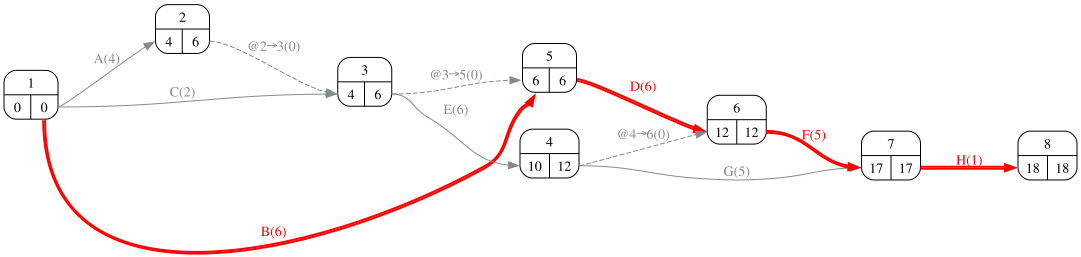

In [10]:
#| fig-cap: "Grafo PERT con el camino crítico"
#| label: fig-grafo
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [11]:
pagos = pd.Series(0.0, index=range(1, duracion + 1))
for act, fila in datos_proyecto.iterrows():
    es, d = int(calendario.loc[act, 'inicio_mas_temprano']), int(fila['duration'])
    for mes in range(es + 1, es + d + 1):
        pagos[mes] += fila['BAC'] / d
flujos = [0.0] + [-float(x) for x in pagos] + [F] * N
VAN_det = van(flujos, k_mensual)
criticas = calendario.index[calendario['H_total'] == 0].tolist()
Markdown(f'Duración {duracion} meses; actividades críticas: {", ".join(criticas)}. Inversión Σ BAC = {I0:.0f} k€. '
         f'Con k mensual = {k_mensual:.4%}, el VAN determinista es {VAN_det:.1f} k€.')

Duración 18 meses; actividades críticas: B, D, F, H. Inversión Σ BAC = 1075 k€. Con k mensual = 0.7974%, el VAN determinista es 226.0 k€.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Simule 5 000 réplicas: duraciones triangulares e ingreso mensual incierto. De cada réplica obtenga la duración del proyecto y su VAN. Dibuje los histogramas y calcule la media, la desviación típica, P(VAN < 0) y el percentil 5 %.  

In [13]:
distribuciones = {act: ('triangular', float(f['a']), float(f['m']), float(f['b'])) for act, f in datos_proyecto.iterrows()}
ingreso = ('triangular', F - delta, F, F + delta)
mc = proyecto.monte_carlo_van(distribuciones, datos_proyecto['BAC'], ingreso, N, k, n_samples=5000, seed=2025)
resumen = mc.summary().round(2)
resumen

,media,desv. típica,q05,q50,q95,P(VAN<0),CVaR 5%
VAN,222.0,166.46,-59.78,222.12,499.88,0.1,-101.11


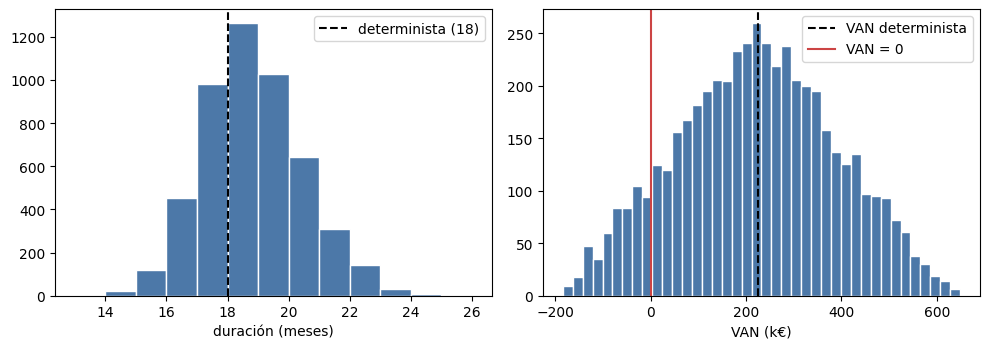

In [14]:
#| fig-cap: "Distribución de la duración del proyecto y del VAN (5 000 réplicas)"
#| label: fig-histogramas
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
ejes[0].hist(mc.tau_samples, bins=range(int(mc.tau_samples.min()), int(mc.tau_samples.max()) + 2), color='#4c78a8', edgecolor='white')
ejes[0].axvline(duracion, color='k', ls='--', label=f'determinista ({duracion})'); ejes[0].set_xlabel('duración (meses)'); ejes[0].legend()
ejes[1].hist(mc.van_samples, bins=40, color='#4c78a8', edgecolor='white')
ejes[1].axvline(VAN_det, color='k', ls='--', label='VAN determinista'); ejes[1].axvline(0, color='#c44', label='VAN = 0')
ejes[1].set_xlabel('VAN (k€)'); ejes[1].legend(); plt.tight_layout()

In [15]:
Markdown(f'La duración media es {mc.tau_samples.mean():.2f} meses frente a {duracion} del plan; el VAN medio es {mc.van_mean:.1f} k€ '
         f'(determinista {VAN_det:.1f}), con desviación {mc.van_std:.1f}. P(VAN < 0) = {mc.prob_negativo:.1%} y el percentil 5 % es {mc.cuantil(0.05):.1f} k€.')

La duración media es 18.34 meses frente a 18 del plan; el VAN medio es 222.0 k€ (determinista 226.0), con desviación 166.5. P(VAN < 0) = 10.3% y el percentil 5 % es -59.8 k€.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. ¿Por qué la media del VAN simulado no coincide con el VAN determinista? Separe los dos efectos simulando por separado solo la incertidumbre de las duraciones y solo la del ingreso.  

In [17]:
fijas = {act: ('uniform', float(f['duration']), float(f['duration'])) for act, f in datos_proyecto.iterrows()}
solo_duraciones = proyecto.monte_carlo_van(distribuciones, datos_proyecto['BAC'], F, N, k, n_samples=5000, seed=2025)
solo_ingreso = proyecto.monte_carlo_van(fijas, datos_proyecto['BAC'], ingreso, N, k, n_samples=5000, seed=2025)
filas = {'VAN determinista': (VAN_det, 0.0, float(VAN_det < 0))}
for nombre, r in {'solo duraciones inciertas': solo_duraciones, 'solo ingreso incierto': solo_ingreso, 'ambas': mc}.items():
    filas[nombre] = (r.van_mean, r.van_std, r.prob_negativo)
tabla = pd.DataFrame(filas, index=['VAN medio', 'desviación', 'P(VAN < 0)']).T
display(tabla.round(3))
ee_ing, ee_dur = 2 * solo_ingreso.van_std / np.sqrt(5000), 2 * solo_duraciones.van_std / np.sqrt(5000)
Markdown(f'La incertidumbre del ingreso (simétrica y lineal en el VAN) ensancha la distribución pero no mueve la media: '
         f'{solo_ingreso.van_mean:.1f} ± {ee_ing:.1f} (dos errores estándar de simulación) frente a {VAN_det:.1f}. Las duraciones sí la bajan, hasta '
         f'{solo_duraciones.van_mean:.1f} ± {ee_dur:.1f}: el proyecto termina cuando termina el último camino, así que la duración media es '
         f'{solo_duraciones.tau_samples.mean():.2f} > {duracion} (caminos casi críticos que se fusionan) y cada mes de retraso retrasa un flujo descontado. '
         'Es el mismo sesgo de la aproximación normal, ahora medido en k€.')

,VAN medio,desviación,P(VAN < 0)
VAN determinista,225.968,0.000,0.000
solo duraciones inciertas,223.277,12.452,0.000
solo ingreso incierto,221.351,168.705,0.107
ambas,222.004,166.455,0.103


La incertidumbre del ingreso (simétrica y lineal en el VAN) ensancha la distribución pero no mueve la media: 221.4 ± 4.8 (dos errores estándar de simulación) frente a 226.0. Las duraciones sí la bajan, hasta 223.3 ± 0.4: el proyecto termina cuando termina el último camino, así que la duración media es 18.34 > 18 (caminos casi críticos que se fusionan) y cada mes de retraso retrasa un flujo descontado. Es el mismo sesgo de la aproximación normal, ahora medido en k€.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. ¿Qué variables explican la variabilidad del VAN? Calcule la correlación de Spearman del VAN con cada duración y con el ingreso, y compárela con el índice de criticidad de cada actividad. ¿Hay alguna actividad cuya demora *mejore* el VAN? ¿Por qué?  

In [19]:
tornado = mc.tornado()
criticidad = proyecto.monte_carlo(distribuciones, n_samples=5000, seed=2025).sensitivity_mean
comparacion = pd.DataFrame({'Spearman con el VAN': tornado['Spearman con el VAN']})
comparacion['índice de criticidad'] = [criticidad.get(v.split()[-1], np.nan) if v.startswith('duración') else np.nan for v in comparacion.index]
display(comparacion.round(3))
positivas = [v for v, r in tornado['Spearman con el VAN'].items() if r > 0.02 and v.startswith('duración')]
Markdown(f'Mandan el ingreso y las actividades con alto índice de criticidad (su retraso retrasa el cobro). '
         f'Con correlación positiva apreciable: {positivas or "ninguna"}. Una actividad con holgura que se alarga no retrasa el cobro y '
         'desplaza el pago de su BAC hacia meses más descontados, por lo que puede mejorar ligeramente el VAN; el efecto es pequeño.')

,Spearman con el VAN,índice de criticidad
ingreso mensual,0.997,NaN
duración F,-0.061,0.841
duración B,-0.034,0.700
duración D,-0.026,0.753
duración G,0.018,0.159
duración A,0.014,0.298
duración C,0.012,0.002
duración E,-0.007,0.247


Mandan el ingreso y las actividades con alto índice de criticidad (su retraso retrasa el cobro). Con correlación positiva apreciable: ninguna. Una actividad con holgura que se alarga no retrasa el cobro y desplaza el pago de su BAC hacia meses más descontados, por lo que puede mejorar ligeramente el VAN; el efecto es pequeño.

## Apartado 5

In [20]:
display(Markdown(pregunta_5))

5. La empresa puede (a) encargar un estudio de mercado que fije el ingreso en su valor central, o (b) contratar a un subcontratista que fije la duración de la actividad más influyente en su valor esperado. Evalúe qué cambia con cada opción (y con ambas) en la media, la desviación y P(VAN < 0), y qué compra realmente cada una.  

In [21]:
influyente = tornado.index[[v.startswith('duración') for v in tornado.index]][0].split()[-1]
centrada = dict(distribuciones); centrada[influyente] = ('uniform', float(datos_proyecto.loc[influyente, 'duration']), float(datos_proyecto.loc[influyente, 'duration']))
opciones = {'sin hacer nada': mc,
            '(a) fijar el ingreso': proyecto.monte_carlo_van(distribuciones, datos_proyecto['BAC'], F, N, k, n_samples=5000, seed=2025),
            f'(b) fijar la duración de {influyente}': proyecto.monte_carlo_van(centrada, datos_proyecto['BAC'], ingreso, N, k, n_samples=5000, seed=2025),
            '(a) y (b)': proyecto.monte_carlo_van(centrada, datos_proyecto['BAC'], F, N, k, n_samples=5000, seed=2025)}
tabla_op = pd.DataFrame({n: (r.van_mean, r.van_std, r.prob_negativo, r.cvar(0.05)) for n, r in opciones.items()},
                        index=['VAN medio', 'desviación', 'P(VAN < 0)', 'CVaR 5 %']).T
display(tabla_op.round(3))
mejor_riesgo = tabla_op.drop(index=['sin hacer nada', '(a) y (b)'])['P(VAN < 0)'].idxmin()
Markdown(f'La actividad más influyente es {influyente}. Fijar el ingreso o una duración cambia poco el VAN medio '
         f'({tabla_op.loc["sin hacer nada", "VAN medio"]:.1f} → entre {tabla_op["VAN medio"].drop("sin hacer nada").min():.1f} y {tabla_op["VAN medio"].drop("sin hacer nada").max():.1f}): '
         f'lo que compra es seguridad. La opción que más reduce P(VAN < 0) es {mejor_riesgo}. Si la empresa es neutral al riesgo, solo vale la pena pagar '
         'por lo que sube la media; si le preocupa la cola (P(VAN < 0), CVaR), se paga por reducir dispersión.')

,VAN medio,desviación,P(VAN < 0),CVaR 5 %
sin hacer nada,222.004,166.455,0.103,-101.111
(a) fijar el ingreso,223.277,12.452,0.000,194.718
(b) fijar la duración de F,222.324,166.235,0.103,-100.694
(a) y (b),223.623,11.106,0.000,197.590


La actividad más influyente es F. Fijar el ingreso o una duración cambia poco el VAN medio (222.0 → entre 222.3 y 223.6): lo que compra es seguridad. La opción que más reduce P(VAN < 0) es (a) fijar el ingreso. Si la empresa es neutral al riesgo, solo vale la pena pagar por lo que sube la media; si le preocupa la cola (P(VAN < 0), CVaR), se paga por reducir dispersión.